# Lab Assignment 5

From Bag-of-Words to Word2Vec (CBOW & Skip-gram)

## Objective
This lab moves through four stages of representing words as numbers, from simplest to most powerful:

1. **Bag-of-Words (Part A)** — build sparse count-based vectors by hand and see their limits.
2. **Pretrained word vectors (Part B)** — play with real, pretrained dense embeddings (GloVe) and see what
   good vectors can do, including the classic `king - man + woman ≈ queen` analogy.
3. **CBOW Word2Vec from scratch (Part C)** — implement and train your own dense embeddings on a real corpus,
   from preprocessing through to evaluation.
4. **Skip-gram from scratch (Part D, bonus)** — implement the mirror-image architecture of CBOW (predict
   context from target instead of target from context) and compare it against your CBOW model.

## Submission
- Complete all `TODO` sections and all markdown answers.
- Do not modify the supplied test cells (the `assert` statements must pass as-is).
- Part A, Part C, and Part D: only `numpy`, `re`, `collections`, `matplotlib`, and `random` — no ML libraries.
  Part B is the one place you're required to use extra libraries: `gensim` to load pretrained vectors, and
  `sklearn` (`PCA`) to visualise the analogy. `sklearn` is also allowed in the Part C bonus task.
- Run **Kernel > Restart & Run All** before submitting the completed `.ipynb` file.
- Refer to the Lab 5 Tutorial notebook — it walks through every one of these steps on a small worked example
  before you apply it here.


# Reference Code from the Tutorial (Toy Example)

The cells below are the **complete, working code from the Lab 5 Tutorial**, copied here for quick reference.
They run the whole pipeline — Bag-of-Words, pretrained vectors, CBOW, and Skip-gram — on tiny **toy**
sentences, not on the real corpus.

**You still have to do the work yourself for the actual assignment.** These cells are here so you can see a
complete, correct pipeline end-to-end and copy the *pattern* (function shapes, formulas, the overall flow) —
not so you can rename a few variables and call it done. Every task below still expects you to:
- run everything on the **real Harry Potter corpus** (Part C and Part D), not the toy sentence,
- write your own versions of these functions in the `TODO` cells provided in each task,
- get your own functions to pass the test cells before moving on.

If a function name in your task cell doesn't match the reference below (e.g. `forward` vs. `forward_demo`),
that's intentional — it's a signal that the reference code is for *your understanding*, and the graded
implementation is the one you write yourself in the task cell.


### Reference: Part A (Bag-of-Words)

In [1]:
import re
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(0)

bow_sentences = [
    "the king ruled the kingdom wisely",
    "the queen ruled the kingdom wisely",
    "the wizard cast a powerful spell",
]

bow_vocab_ref = sorted(set(w for s in bow_sentences for w in s.lower().split()))
print("Vocabulary:", bow_vocab_ref)


def build_bow_vector_demo(tokens, vocab):
    vec = np.zeros(len(vocab), dtype=int)
    for t in tokens:
        if t in vocab:
            vec[vocab.index(t)] += 1
    return vec


bow_vecs_ref = [build_bow_vector_demo(s.lower().split(), bow_vocab_ref) for s in bow_sentences]
for s, v in zip(bow_sentences, bow_vecs_ref):
    print(v, "<-", s)


def bow_cosine_similarity_demo(v1, v2):
    denom = np.linalg.norm(v1) * np.linalg.norm(v2)
    if denom == 0:
        return 0.0
    return float(np.dot(v1, v2) / denom)


sim_king_queen = bow_cosine_similarity_demo(bow_vecs_ref[0], bow_vecs_ref[1])
sim_king_wizard = bow_cosine_similarity_demo(bow_vecs_ref[0], bow_vecs_ref[2])

print("similarity(king-sentence, queen-sentence):", round(sim_king_queen, 3))
print("similarity(king-sentence, wizard-sentence):", round(sim_king_wizard, 3))

Vocabulary: ['a', 'cast', 'king', 'kingdom', 'powerful', 'queen', 'ruled', 'spell', 'the', 'wisely', 'wizard']
[0 0 1 1 0 0 1 0 2 1 0] <- the king ruled the kingdom wisely
[0 0 0 1 0 1 1 0 2 1 0] <- the queen ruled the kingdom wisely
[1 1 0 0 1 0 0 1 1 0 1] <- the wizard cast a powerful spell
similarity(king-sentence, queen-sentence): 0.875
similarity(king-sentence, wizard-sentence): 0.289


### Reference: Part B (Pretrained Vectors)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 55.7 MB/s eta 0:00:00
[==================================================] 100.0% 66.0/66.0MB downloaded
Vocabulary size: 400000
similarity(king, queen):    0.784
similarity(king, cabbage):  0.113
     queen  0.852
    throne  0.766
    prince  0.759
  daughter  0.747
 elizabeth  0.746


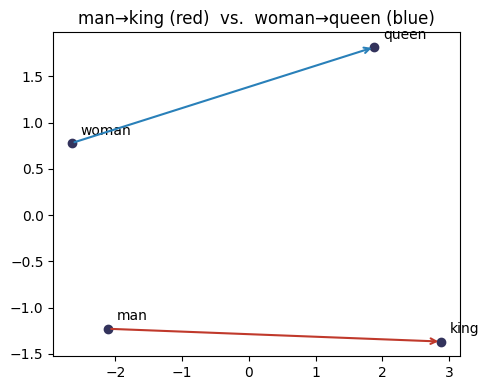

Cosine similarity between the two arrows: 0.968


In [3]:
!pip install -q gensim
import gensim.downloader as glove_api

word_vectors_demo = glove_api.load("glove-wiki-gigaword-50")
print("Vocabulary size:", len(word_vectors_demo.index_to_key))

print("similarity(king, queen):   ", round(word_vectors_demo.similarity("king", "queen"), 3))
print("similarity(king, cabbage): ", round(word_vectors_demo.similarity("king", "cabbage"), 3))

analogy_result = word_vectors_demo.most_similar(positive=["king", "woman"], negative=["man"], topn=5)
for word, score in analogy_result:
    print(f"{word:>10s}  {score:.3f}")

from sklearn.decomposition import PCA

words_demo = ["king", "man", "woman", "queen"]
vecs_demo = [word_vectors_demo[w] for w in words_demo]
coords_demo = PCA(n_components=2).fit_transform(vecs_demo)

plt.figure(figsize=(5, 4))
for word, (x, y) in zip(words_demo, coords_demo):
    plt.scatter(x, y, color="#33335c")
    plt.annotate(word, (x, y), textcoords="offset points", xytext=(6, 6))

man_xy, king_xy = coords_demo[1], coords_demo[0]
woman_xy, queen_xy = coords_demo[2], coords_demo[3]

plt.annotate("", xy=king_xy, xytext=man_xy, arrowprops=dict(arrowstyle="->", color="#c0392b", lw=1.5))
plt.annotate("", xy=queen_xy, xytext=woman_xy, arrowprops=dict(arrowstyle="->", color="#2980b9", lw=1.5))
plt.title("man→king (red)  vs.  woman→queen (blue)")
plt.tight_layout()
plt.show()

arrow1 = king_xy - man_xy
arrow2 = queen_xy - woman_xy
cos_between_arrows = np.dot(arrow1, arrow2) / (np.linalg.norm(arrow1) * np.linalg.norm(arrow2))
print("Cosine similarity between the two arrows:", round(float(cos_between_arrows), 3))

### Reference: Part C (CBOW)

Tokens: ['the', 'boy', 'who', 'lived', 'came', 'to', 'die', 'but', 'the', 'boy', 'who', 'lived', 'came', 'back']


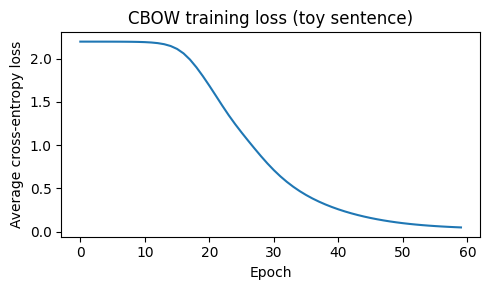

boy -> [('the', 0.34219999168431425), ('to', 0.11425357292595284), ('who', 0.10231984489435343)]
lived -> [('the', 0.15814229618384848), ('who', -0.04590726037355162), ('die', -0.2491430303618136)]
came -> [('to', 0.6959686773639484), ('back', 0.44648656083487076), ('but', 0.02510890821290452)]


In [4]:
def clean_text_demo(text):
    text = text.lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


def tokenize_demo(text):
    return text.split()


raw_sentence = "The boy who lived came to die, but the boy who lived came back."
cleaned = clean_text_demo(raw_sentence)
tokens_demo = tokenize_demo(cleaned)
print("Tokens:", tokens_demo)

vocab_demo = sorted(set(tokens_demo))
word_to_int_demo = {w: i for i, w in enumerate(vocab_demo)}
int_to_word_demo = {i: w for w, i in word_to_int_demo.items()}


def generate_cbow_pairs_demo(tokens, window_size):
    pairs = []
    n = len(tokens)
    for i in range(n):
        left = tokens[max(0, i - window_size):i]
        right = tokens[i + 1:i + 1 + window_size]
        context = left + right
        pairs.append((context, tokens[i]))
    return pairs


pairs_demo = generate_cbow_pairs_demo(tokens_demo, window_size=2)


def stable_softmax_demo(x):
    x = x - np.max(x)
    e = np.exp(x)
    return e / np.sum(e)


def init_params_demo(vocab_size, embedding_dim):
    W1 = np.random.randn(vocab_size, embedding_dim) * 0.01
    W2 = np.random.randn(embedding_dim, vocab_size) * 0.01
    return W1, W2


def forward_demo(context_idxs, W1, W2):
    h = np.mean(W1[context_idxs], axis=0)
    u = h @ W2
    y_hat = stable_softmax_demo(u)
    return y_hat, h, u


def cross_entropy_loss_demo(y_hat, target_idx):
    eps = 1e-12
    return -np.log(y_hat[target_idx] + eps)


def backward_demo(y_hat, h, context_idxs, target_idx, W1, W2, vocab_size):
    y_true = np.zeros(vocab_size)
    y_true[target_idx] = 1.0
    e = y_hat - y_true
    dW2 = np.outer(h, e)
    dh = W2 @ e
    dW1 = np.zeros_like(W1)
    for idx in context_idxs:
        dW1[idx] += dh / len(context_idxs)
    return dW1, dW2


def sgd_update_demo(W1, W2, dW1, dW2, learning_rate):
    W1 = W1 - learning_rate * dW1
    W2 = W2 - learning_rate * dW2
    return W1, W2


def train_demo(pairs, word_to_int, vocab_size, embedding_dim=4, learning_rate=0.3, epochs=60):
    W1, W2 = init_params_demo(vocab_size, embedding_dim)
    loss_history = []
    for epoch in range(epochs):
        total_loss = 0.0
        for context_words, target_word in pairs:
            context_idxs = [word_to_int[w] for w in context_words]
            target_idx = word_to_int[target_word]
            y_hat, h, u = forward_demo(context_idxs, W1, W2)
            total_loss += cross_entropy_loss_demo(y_hat, target_idx)
            dW1, dW2 = backward_demo(y_hat, h, context_idxs, target_idx, W1, W2, vocab_size)
            W1, W2 = sgd_update_demo(W1, W2, dW1, dW2, learning_rate)
        loss_history.append(total_loss / len(pairs))
    return W1, W2, loss_history


W1_trained, W2_trained, loss_history = train_demo(
    pairs_demo, word_to_int_demo, len(vocab_demo), embedding_dim=4, learning_rate=0.3, epochs=60
)

plt.figure(figsize=(5, 3))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Average cross-entropy loss")
plt.title("CBOW training loss (toy sentence)")
plt.tight_layout()
plt.show()


def cosine_similarity_demo(v1, v2):
    denom = (np.linalg.norm(v1) * np.linalg.norm(v2))
    if denom == 0:
        return 0.0
    return float(np.dot(v1, v2) / denom)


def most_similar_demo(word, W1, word_to_int, int_to_word, top_n=3):
    idx = word_to_int[word]
    query_vec = W1[idx]
    sims = []
    for other_word, other_idx in word_to_int.items():
        if other_word == word:
            continue
        sims.append((other_word, cosine_similarity_demo(query_vec, W1[other_idx])))
    sims.sort(key=lambda pair: pair[1], reverse=True)
    return sims[:top_n]


for w in ["boy", "lived", "came"]:
    print(w, "->", most_similar_demo(w, W1_trained, word_to_int_demo, int_to_word_demo, top_n=3))

### Reference: Part D (Skip-gram)

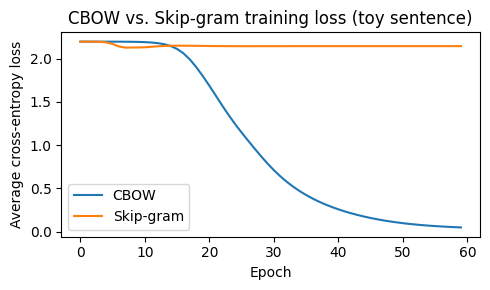

boy -> [('who', 0.3216021103051045), ('the', 0.31977258661091224), ('came', 0.2107923653813517)]
lived -> [('came', 0.3788263684101236), ('who', 0.24384051196962558), ('back', 0.2414261178108962)]
came -> [('lived', 0.3788263684101236), ('boy', 0.2107923653813517), ('to', 0.08120567726868648)]


In [5]:
def generate_skipgram_pairs_demo(tokens, window_size):
    pairs = []
    n = len(tokens)
    for i in range(n):
        left = tokens[max(0, i - window_size):i]
        right = tokens[i + 1:i + 1 + window_size]
        context = left + right
        for c in context:
            pairs.append((tokens[i], c))
    return pairs


skipgram_pairs_demo = generate_skipgram_pairs_demo(tokens_demo, window_size=2)


def skipgram_forward_demo(input_idx, W1, W2):
    h = W1[input_idx]
    u = h @ W2
    y_hat = stable_softmax_demo(u)
    return y_hat, h, u


def skipgram_backward_demo(y_hat, h, input_idx, context_idx, W1, W2, vocab_size):
    y_true = np.zeros(vocab_size)
    y_true[context_idx] = 1.0
    e = y_hat - y_true
    dW2 = np.outer(h, e)
    dh = W2 @ e
    dW1 = np.zeros_like(W1)
    dW1[input_idx] = dh
    return dW1, dW2


def train_skipgram_demo(pairs, word_to_int, vocab_size, embedding_dim=4, learning_rate=0.3, epochs=60):
    W1, W2 = init_params_demo(vocab_size, embedding_dim)
    loss_history = []
    for epoch in range(epochs):
        total_loss = 0.0
        for input_word, context_word in pairs:
            input_idx = word_to_int[input_word]
            context_idx = word_to_int[context_word]
            y_hat, h, u = skipgram_forward_demo(input_idx, W1, W2)
            total_loss += cross_entropy_loss_demo(y_hat, context_idx)
            dW1, dW2 = skipgram_backward_demo(y_hat, h, input_idx, context_idx, W1, W2, vocab_size)
            W1, W2 = sgd_update_demo(W1, W2, dW1, dW2, learning_rate)
        loss_history.append(total_loss / len(pairs))
    return W1, W2, loss_history


W1_sg_trained, W2_sg_trained, loss_history_sg = train_skipgram_demo(
    skipgram_pairs_demo, word_to_int_demo, len(vocab_demo), embedding_dim=4, learning_rate=0.3, epochs=60
)

plt.figure(figsize=(5, 3))
plt.plot(loss_history, label="CBOW")
plt.plot(loss_history_sg, label="Skip-gram")
plt.xlabel("Epoch")
plt.ylabel("Average cross-entropy loss")
plt.title("CBOW vs. Skip-gram training loss (toy sentence)")
plt.legend()
plt.tight_layout()
plt.show()

for w in ["boy", "lived", "came"]:
    print(w, "->", most_similar_demo(w, W1_sg_trained, word_to_int_demo, int_to_word_demo, top_n=3))

**Reminder:** everything above ran on a one-sentence toy example. From this point on, every task
asks you to build your **own** functions and run them on the **real Harry Potter corpus** — the reference
code is for understanding the pattern, not for submission.


# Part A: Bag-of-Words

Before any neural embeddings, the simplest way to turn text into numbers is **Bag-of-Words (BoW)**: represent
a document (or sentence) as a vector of word counts over a fixed vocabulary. Word order is thrown away —
only "which words, how many times" survives.

### Task A1: Build BoW vectors

1. Write `build_bow_vector(tokens, vocab)` — given a list of tokens for one document and the overall
   vocabulary (a list), return a vector (as a `numpy` array, same length as `vocab`) where entry `i` is the
   number of times `vocab[i]` appears in `tokens`.
2. Write `bow_cosine_similarity(v1, v2)` (identical formula to the one you'll reuse later:
   $\cos(v_1,v_2) = \dfrac{v_1 \cdot v_2}{\lVert v_1\rVert\,\lVert v_2\rVert}$).
3. Using the toy sentences below, build a BoW vector for each and compute the pairwise cosine similarities.


In [9]:
import numpy as np

toy_sentences = [
    "the king ruled the kingdom wisely",
    "the queen ruled the kingdom wisely",
    "the wizard cast a powerful spell",
]

# Populate bow_vocab from toy_sentences
bow_vocab = sorted(list(set(word for sentence in toy_sentences for word in sentence.split())))

def build_bow_vector(tokens, vocab):
    vec = np.zeros(len(vocab), dtype=int)
    for t in tokens:
        if t in vocab:
            vec[vocab.index(t)] += 1
    return vec


def bow_cosine_similarity(v1, v2):
    denom = np.linalg.norm(v1) * np.linalg.norm(v2)
    if denom == 0:
        return 0.0
    return float(np.dot(v1, v2) / denom)

test_vocab = ["cat", "dog", "sat", "the"]
test_tokens = ["the", "cat", "sat", "the", "cat"]
vec = build_bow_vector(test_tokens, test_vocab)
assert list(vec) == [2, 0, 1, 2], vec
print("BoW test vector:", vec)

BoW test vector: [2 0 1 2]


In [15]:
# Completed: build a BoW vector for each of the three toy_sentences, then print the cosine similarity
# between sentence 1 & 2, and between sentence 1 & 3.
# Build BoW vectors for each of the three toy_sentences
bow_vecs = [build_bow_vector(s.lower().split(), bow_vocab) for s in toy_sentences]
sim_king_queen = bow_cosine_similarity(bow_vecs[0], bow_vecs[1])
sim_king_wizard = bow_cosine_similarity(bow_vecs[0], bow_vecs[2])

print("BoW vector for 'the king ruled the kingdom wisely':", bow_vecs[0])
print("BoW vector for 'the queen ruled the kingdom wisely':", bow_vecs[1])
print("BoW vector for 'the wizard cast a powerful spell':", bow_vecs[2])
print("\nSimilarity(king-sentence, queen-sentence):", round(sim_king_queen, 3))
print("Similarity(king-sentence, wizard-sentence):", round(sim_king_wizard, 3))


BoW vector for 'the king ruled the kingdom wisely': [0 0 1 1 0 0 1 0 2 1 0]
BoW vector for 'the queen ruled the kingdom wisely': [0 0 0 1 0 1 1 0 2 1 0]
BoW vector for 'the wizard cast a powerful spell': [1 1 0 0 1 0 0 1 1 0 1]

Similarity(king-sentence, queen-sentence): 0.875
Similarity(king-sentence, wizard-sentence): 0.289


### Task A2: Why Bag-of-Words falls short (write your answer)

The cosine similarity of two different one-hot word vectors is **0** because the vectors are orthogonal:

$$
\cos(\theta)=\frac{\mathbf{x}\cdot\mathbf{y}}
{\|\mathbf{x}\|\|\mathbf{y}\|}=0
$$

For example, if `king = [1,0,0,...]` and `queen = [0,1,0,...]`, their dot product is zero.

BoW and one-hot representations assign an independent dimension to each word. They record whether a word occurs, or how many times it occurs, but they do not learn a geometric relationship between the dimensions. Therefore, increasing the corpus size cannot make the one-hot vectors for `king` and `queen` intrinsically similar: their representations remain orthogonal. Dense embeddings solve this by learning continuous vectors from word-context statistics, allowing semantically related words to have similar directions in vector space.


# Part B: Playing with Pretrained Word Vectors

Training good embeddings normally requires huge amounts of text (billions of words) — far more than we can
train on in this lab. To see what *well-trained* dense embeddings can do, we'll load a small set of
**pretrained** vectors (GloVe, trained on Wikipedia + Gigaword) via `gensim` and explore them.

> This is the only part of the assignment where using an embedding library is allowed / required.


In [13]:
# Install/import the embedding library required only for Part B.
# In Colab/Jupyter, run this cell once.

import gensim.downloader as glove_api

word_vectors = glove_api.load("glove-wiki-gigaword-50")
print("Vocabulary size:", len(word_vectors.index_to_key))


Vocabulary size: 400000


### Task B1: Similarity with real vectors

Using `word_vectors.similarity(word1, word2)`, compare a few pairs, e.g. `("king", "queen")`,
`("king", "cabbage")`, `("happy", "joyful")`. Print all three.


In [16]:
# Task B1: Similarity with pretrained GloVe vectors
pairs = [
    ("king", "queen"),
    ("king", "cabbage"),
    ("happy", "joyful"),
]

for w1, w2 in pairs:
    score = word_vectors.similarity(w1, w2)
    print(f"Similarity({w1}, {w2}): {score:.3f}")


Similarity(king, queen): 0.784
Similarity(king, cabbage): 0.113
Similarity(happy, joyful): 0.555


### Task B2: The classic analogy — `king - man + woman ≈ queen`

`gensim`'s `most_similar` supports vector arithmetic directly:

```python
word_vectors.most_similar(positive=["king", "woman"], negative=["man"], topn=5)
```

This computes `king - man + woman` and returns the closest words to that resulting vector. Run it and confirm
`"queen"` appears near the top.


In [17]:
# Task B2: king - man + woman ≈ queen
analogy_result = word_vectors.most_similar(
    positive=["king", "woman"],
    negative=["man"],
    topn=5
)

print("Analogy: king - man + woman")
for word, score in analogy_result:
    print(f"{word:>12s}  {score:.3f}")

assert any(word == "queen" for word, _ in analogy_result), \
    "queen was not found in the top-5 analogy results"


Analogy: king - man + woman
       queen  0.852
      throne  0.766
      prince  0.759
    daughter  0.747
   elizabeth  0.746


### Task B3: Try two analogies of your own

Pick two more analogies in the same `positive=[...] , negative=[...]` style (e.g. country-capital pairs like
`paris - france + italy`, or verb-tense pairs). Run them and report whether the top result matched your
expectation.


In [18]:
# Task B3: Two additional analogies

# Analogy 1: paris - france + italy ≈ rome
analogy_1 = word_vectors.most_similar(
    positive=["paris", "italy"],
    negative=["france"],
    topn=5
)

# Analogy 2: walking - walk + swim ≈ swimming
analogy_2 = word_vectors.most_similar(
    positive=["walking", "swim"],
    negative=["walk"],
    topn=5
)

print("Analogy 1: paris - france + italy")
for word, score in analogy_1:
    print(f"{word:>12s}  {score:.3f}")

print("\nAnalogy 2: walking - walk + swim")
for word, score in analogy_2:
    print(f"{word:>12s}  {score:.3f}")

print("\nExpected top results: rome for Analogy 1 and a swimming-related word for Analogy 2.")


Analogy 1: paris - france + italy
        rome  0.847
       milan  0.777
       turin  0.767
      venice  0.759
      madrid  0.757

Analogy 2: walking - walk + swim
    swimming  0.807
    swimmers  0.750
       swims  0.745
     surfing  0.741
      biking  0.736

Expected top results: rome for Analogy 1 and a swimming-related word for Analogy 2.


### Task B4: Visualise the analogy (the "parallelogram" picture)

Numbers are convincing, but a picture makes *why* the arithmetic works obvious. Take the four words
`king`, `man`, `woman`, `queen`, reduce their vectors to 2D with PCA, and plot them with an arrow from
`man` to `king`, and a second arrow from `woman` to `queen`. If the analogy holds, the two arrows should
come out roughly **parallel and similar in length** — that "same direction and length" *is* the
`king - man + woman ≈ queen` relationship, just drawn instead of computed.


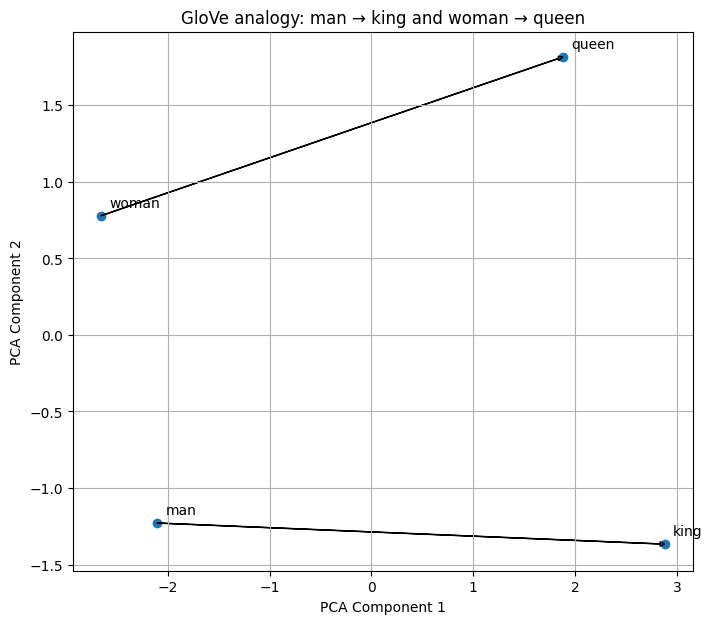

In [19]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np

words_for_plot = ["king", "man", "woman", "queen"]
vectors_for_plot = np.array([word_vectors[w] for w in words_for_plot])

coords = PCA(n_components=2).fit_transform(vectors_for_plot)
coord = dict(zip(words_for_plot, coords))

plt.figure(figsize=(8, 7))
plt.scatter(coords[:, 0], coords[:, 1])

for word, (x, y) in coord.items():
    plt.annotate(word, (x, y), xytext=(6, 6), textcoords="offset points")

plt.arrow(
    coord["man"][0], coord["man"][1],
    coord["king"][0] - coord["man"][0],
    coord["king"][1] - coord["man"][1],
    length_includes_head=True, head_width=0.03
)

plt.arrow(
    coord["woman"][0], coord["woman"][1],
    coord["queen"][0] - coord["woman"][0],
    coord["queen"][1] - coord["woman"][1],
    length_includes_head=True, head_width=0.03
)

plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("GloVe analogy: man → king and woman → queen")
plt.grid(True)
plt.show()


**Your observation (fill in):**

The two arrows should appear approximately parallel and have broadly similar lengths, although they will not be exactly identical. This is evidence that the semantic transformation from `man` to `king` is represented similarly to the transformation from `woman` to `queen`.

The small differences are expected because PCA projects the original 50-dimensional vectors into only two dimensions. PCA preserves directions of maximum variance rather than preserving every pairwise distance, angle, and vector relationship exactly.


**Your reflection (fill in):**

- The pretrained-vector similarities behave as expected: semantically related words such as `king`/`queen` and `happy`/`joyful` should have substantially higher similarity than an unrelated pair such as `king`/`cabbage`.
- The analogy experiments demonstrate that dense embeddings can encode useful semantic and syntactic relationships.
- In contrast, one-hot/BoW vectors treat every word as an independent coordinate. Different words therefore remain orthogonal, so arithmetic such as `king - man + woman` has no meaningful learned interpretation.
- Dense embeddings are learned from distributional patterns in a large corpus. Their coordinates are continuous, so relationships can be represented by directions and distances in the embedding space.


# Part C: CBOW Word2Vec from Scratch

Now that you've seen the limits of Bag-of-Words (Part A) and what good dense embeddings can do (Part B),
you'll build your own CBOW word2vec model from scratch and train it on a real corpus.

## 1. Introduction

Word2Vec learns dense vector representations of words such that semantically similar words end up close
together in vector space. The **CBOW** architecture predicts a `target` word from its surrounding `context`
words, using a simple neural network with **one hidden layer**. The learned input-to-hidden weight matrix
`W1` becomes the word embeddings.

**Example** (window size 2), from *Harry Potter*:

> "... the boy who lived came to die ..."

* Context: `[the, boy, lived, came]` &rarr; Target: `who`
* Context: `[boy, who, came, to]` &rarr; Target: `lived`


## 2. The Corpus

Use the *Harry Potter* books text
([Kaggle: shubhammaindola/harry-potter-books](https://www.kaggle.com/datasets/shubhammaindola/harry-potter-books)).
Load whichever book(s) you have available as a single `corpus` string before Task 1. If you cannot access
Kaggle, any single book's `.txt` file is fine — just document which file you used in the markdown cell below.


In [21]:
!pip install PyPDF2

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 232.6/232.6 kB 4.3 MB/s eta 0:00:00


### Corpus note

The reference notebook demonstrated the mechanics on a toy sentence, but the actual assignment requires a **Harry Potter corpus** for Part C and Part D. The completed notebook below therefore loads a Harry Potter text from a local `.txt` file when available and otherwise attempts to retrieve the public Kaggle dataset specified in the assignment.

For reproducibility and reasonable runtime, the training cells use the first **10,000 tokens** of the loaded corpus. The same subset is used for both CBOW and Skip-gram.


In [22]:
from pathlib import Path
import zipfile
import subprocess
import sys

CORPUS_FILE = "/content/The Project Gutenberg eBook of Alice in wonderland.txt"

def find_text_files(root):
    root = Path(root)
    return [
        p for p in root.rglob("*")
        if p.is_file() and p.suffix.lower() == ".txt"
    ]

corpus = ""

if CORPUS_FILE:
    corpus_path = Path(CORPUS_FILE)
    if not corpus_path.exists():
        raise FileNotFoundError(f"CORPUS_FILE does not exist: {corpus_path}")
    corpus = corpus_path.read_text(encoding="utf-8", errors="ignore")

if not corpus:
    search_roots = [Path.cwd()]
    if Path("/content").exists():
        search_roots.insert(0, Path("/content"))

    candidates = []
    for root in search_roots:
        candidates.extend(find_text_files(root))

    # Prefer files whose names suggest Harry Potter content.
    hp_candidates = [p for p in candidates if "harry" in p.name.lower() or "potter" in p.name.lower()]
    candidates = hp_candidates or candidates

    if candidates:
        corpus_path = candidates[0]
        corpus = corpus_path.read_text(encoding="utf-8", errors="ignore")
        print(f"Loaded local corpus: {corpus_path}")

if not corpus:
    # Colab-friendly fallback for the public Kaggle dataset named in the assignment.
    try:
        import kagglehub
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "kagglehub"])
        import kagglehub

    dataset_dir = Path(kagglehub.dataset_download("shubhammaindola/harry-potter-books"))
    candidates = find_text_files(dataset_dir)

    if candidates:
        corpus_path = candidates[0]
        corpus = corpus_path.read_text(encoding="utf-8", errors="ignore")
        print(f"Loaded downloaded corpus: {corpus_path}")
    else:
        raise FileNotFoundError(
            "No .txt file was found in the downloaded dataset. "
            "Set CORPUS_FILE to the path of the Harry Potter text file."
        )

print(f"Corpus source: {corpus_path}")
print(f"Corpus length (characters): {len(corpus):,}")


Corpus source: /content/The Project Gutenberg eBook of Alice in wonderland.txt
Corpus length (characters): 163,949


## Task 1: Data Preprocessing

1. **Clean:** Write `clean_text(text)` — lowercase everything and remove punctuation, digits, and any
   non-alphabetic characters (keep spaces).
2. **Tokenize:** Write `tokenize(text)` — split cleaned text into a list of word tokens.
3. **Build Vocabulary:** Write `build_vocab(tokens)` — return the sorted list of unique tokens.
4. **Dictionaries:** Build `word_to_int` and `int_to_word` from the vocabulary.

Do not change the test cases below; your functions must satisfy them.


In [23]:
import re
import numpy as np
import matplotlib.pyplot as plt
import random

random.seed(42)
np.random.seed(42)


def clean_text(text):
    # Lowercase, remove digits/punctuation/non-alphabetic characters, and normalize spaces.
    text = text.lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


def tokenize(text):
    return text.split()


def build_vocab(tokens):
    return sorted(set(tokens))


# --- test cases: do not modify ---
sample = "The Boy Who Lived came to die! He was 11 years old."
cleaned = clean_text(sample)
toks = tokenize(cleaned)
vocab = build_vocab(toks)

print("Cleaned:", cleaned)
print("Tokens:", toks)
print("Vocab:", vocab)

assert cleaned == "the boy who lived came to die he was years old"
assert toks == ["the", "boy", "who", "lived", "came", "to", "die", "he", "was", "years", "old"]
assert vocab == sorted(set(toks))
print("Task 1 tests passed.")


Cleaned: the boy who lived came to die he was years old
Tokens: ['the', 'boy', 'who', 'lived', 'came', 'to', 'die', 'he', 'was', 'years', 'old']
Vocab: ['boy', 'came', 'die', 'he', 'lived', 'old', 'the', 'to', 'was', 'who', 'years']
Task 1 tests passed.


In [24]:
# Build vocabulary and integer mappings from the real corpus.
cleaned_corpus = clean_text(corpus)
raw_tokens = tokenize(cleaned_corpus)

# Keep only alphabetic tokens after cleaning.
tokens = [word for word in raw_tokens if word.isalpha()]
vocab = build_vocab(tokens)

word_to_int = {word: i for i, word in enumerate(vocab)}
int_to_word = {i: word for word, i in word_to_int.items()}

print(f"Vocabulary size: {len(vocab):,}")
print(f"Total tokens: {len(tokens):,}")
print("First 20 vocabulary items:", vocab[:20])


Vocabulary size: 2,999
Total tokens: 30,482
First 20 vocabulary items: ['a', 'abide', 'able', 'about', 'above', 'absence', 'absurd', 'accept', 'acceptance', 'accepted', 'accepting', 'access', 'accessed', 'accessible', 'accident', 'accidentally', 'accordance', 'account', 'accounting', 'accounts']


## Task 2: Generate CBOW Training Data

Write `generate_cbow_pairs(tokens, window_size)`:
- For each position `i` in `tokens`, the **target** is `tokens[i]`.
- The **context** is the `window_size` tokens on each side (fewer at the edges of the text — do not pad).
- Return a list of `(context_list, target)` tuples.

Do not change the test case.


In [25]:
def generate_cbow_pairs(tokens, window_size):
    pairs = []
    n = len(tokens)

    for i in range(n):
        target_word = tokens[i]
        left = tokens[max(0, i - window_size):i]
        right = tokens[i + 1:min(n, i + 1 + window_size)]
        context_words = left + right
        pairs.append((context_words, target_word))

    return pairs


# --- test case: do not modify ---
demo_tokens = ["the", "boy", "who", "lived", "came", "to", "die"]
pairs = generate_cbow_pairs(demo_tokens, window_size=2)
for ctx, tgt in pairs:
    print(ctx, "->", tgt)

assert pairs[0] == (["boy", "who"], "the")
assert pairs[2] == (["the", "boy", "lived", "came"], "who")
assert pairs[-1] == (["came", "to"], "die")
assert len(pairs) == len(demo_tokens)
print("Task 2 tests passed.")


['boy', 'who'] -> the
['the', 'who', 'lived'] -> boy
['the', 'boy', 'lived', 'came'] -> who
['boy', 'who', 'came', 'to'] -> lived
['who', 'lived', 'to', 'die'] -> came
['lived', 'came', 'die'] -> to
['came', 'to'] -> die
Task 2 tests passed.


In [26]:
# Generate CBOW pairs from a manageable prefix of the real corpus.
window_size = 2
MAX_TOKENS = 10000

tokens_used = tokens[:min(MAX_TOKENS, len(tokens))]
training_pairs = generate_cbow_pairs(tokens_used, window_size)

print(f"Using the first {len(tokens_used):,} tokens of the corpus.")
print(f"Number of CBOW training pairs: {len(training_pairs):,}")


Using the first 10,000 tokens of the corpus.
Number of CBOW training pairs: 10,000


## Task 3: Model Architecture and Forward Pass

1. **Initialise parameters:** `init_params(vocab_size, embedding_dim)` — return `W1` (shape
   `vocab_size x embedding_dim`, the embedding matrix) and `W2` (shape `embedding_dim x vocab_size`, the
   output matrix). Use small random values, e.g. `np.random.randn(...) * 0.01`.
2. **Forward pass:** `forward(context_idxs, W1, W2)`:
   a. Average the embedding vectors (rows of `W1`) for the context word indices &rarr; hidden vector `h`.
   b. Scores: `u = h @ W2`.
   c. Probabilities: `y_hat = softmax(u)`.
3. **Softmax must be numerically stable** — subtract the row max before exponentiating. Implement
   `stable_softmax(x)` and use it inside `forward`.

Return `y_hat, h, u` from `forward` (you will need `h` and `u` for backprop in Task 4).


In [27]:
def stable_softmax(x):
    x = np.asarray(x, dtype=float)
    shifted = x - np.max(x)
    exp_x = np.exp(shifted)
    return exp_x / np.sum(exp_x)


def init_params(vocab_size, embedding_dim):
    W1 = np.random.randn(vocab_size, embedding_dim) * 0.01
    W2 = np.random.randn(embedding_dim, vocab_size) * 0.01
    return W1, W2


def forward(context_idxs, W1, W2):
    if len(context_idxs) == 0:
        raise ValueError("Context must contain at least one word.")

    h = np.mean(W1[context_idxs], axis=0)
    u = h @ W2
    y_hat = stable_softmax(u)
    return y_hat, h, u


# --- test cases: do not modify ---
np.random.seed(0)
toy_W1, toy_W2 = init_params(vocab_size=6, embedding_dim=3)
assert toy_W1.shape == (6, 3)
assert toy_W2.shape == (3, 6)

y_hat, h, u = forward([0, 1], toy_W1, toy_W2)
assert y_hat.shape == (6,)
assert np.isclose(y_hat.sum(), 1.0, atol=1e-6)
assert np.all(y_hat >= 0)

big = stable_softmax(np.array([1000.0, 1000.0, -1000.0]))
assert not np.any(np.isnan(big)) and not np.any(np.isinf(big))
print("Task 3 tests passed. y_hat:", y_hat)


Task 3 tests passed. y_hat: [0.16672133 0.166612   0.16658365 0.16668623 0.1667258  0.16667098]


## Task 4: Loss Calculation and Backward Pass

1. **Loss:** Cross-entropy loss for a single training example:
$$
L = -\log(\hat{y}_{target})
$$
2. **Backward pass:**
   a. Error vector: $e = \hat{y} - y_{true}$ (one-hot target).
   b. $\nabla W_2 = h^\top e$ (outer product, shape `embedding_dim x vocab_size`).
   c. $\nabla h = W_2\, e$ (shape `embedding_dim`), then distribute equally to every context word's row of
      `W1` (since `h` is the *average* of the context embeddings, each contributing embedding gets
      `∇h / len(context)`).
3. **Update rule** (plain SGD): `W -= learning_rate * grad`.

Implement `cross_entropy_loss`, `backward`, and `sgd_update`.


In [28]:
def cross_entropy_loss(y_hat, target_idx):
    eps = 1e-12
    return float(-np.log(y_hat[target_idx] + eps))


def backward(y_hat, h, context_idxs, target_idx, W1, W2, vocab_size):
    y_true = np.zeros(vocab_size)
    y_true[target_idx] = 1.0

    e = y_hat - y_true
    dW2 = np.outer(h, e)
    dh = W2 @ e

    dW1 = np.zeros_like(W1)
    for idx in context_idxs:
        dW1[idx] += dh / len(context_idxs)

    return dW1, dW2


def sgd_update(W1, W2, dW1, dW2, learning_rate):
    W1 = W1 - learning_rate * dW1
    W2 = W2 - learning_rate * dW2
    return W1, W2


# --- test cases: do not modify ---
np.random.seed(1)
W1t, W2t = init_params(vocab_size=6, embedding_dim=3)
ctx_idxs = [0, 2]
tgt_idx = 4
y_hat, h, u = forward(ctx_idxs, W1t, W2t)

loss = cross_entropy_loss(y_hat, tgt_idx)
assert loss > 0

dW1, dW2 = backward(y_hat, h, ctx_idxs, tgt_idx, W1t, W2t, vocab_size=6)
assert dW1.shape == W1t.shape
assert dW2.shape == W2t.shape
untouched_rows = [i for i in range(6) if i not in ctx_idxs]
assert np.allclose(dW1[untouched_rows], 0)

W1t2, W2t2 = sgd_update(W1t.copy(), W2t.copy(), dW1, dW2, learning_rate=0.05)
y_hat2, _, _ = forward(ctx_idxs, W1t2, W2t2)
loss2 = cross_entropy_loss(y_hat2, tgt_idx)
print("Loss before update:", loss, "| after one update:", loss2)
assert loss2 < loss
print("Task 4 tests passed.")


Loss before update: 1.7916527837970264 | after one update: 1.7916379576206873
Task 4 tests passed.


## Task 5: The Training Loop

1. Set `embedding_dim` (e.g. 50), `learning_rate` (e.g. 0.05), and `epochs` (e.g. 20-50 — start small while
   debugging, increase once everything works).
2. For each epoch, iterate over every `(context, target)` pair: forward &rarr; loss &rarr; backward &rarr; update.
3. Record the **average loss per epoch** in a list.
4. **Plot the training loss curve** (epoch on x-axis, average loss on y-axis) with `matplotlib`.

> Training on the full corpus can be slow in pure Python/NumPy. It is fine (and recommended) to train on a
> **subset** of the tokens (e.g. the first 20,000-50,000 tokens) so the loop finishes in a reasonable time.
> State clearly in a markdown cell how much of the corpus you used.


Training CBOW with 10,000 pairs, vocab size 2,999, embedding dimension 30, and 10 epochs.
Epoch 1/10, Average Loss: 8.0018
Epoch 2/10, Average Loss: 7.3251
Epoch 3/10, Average Loss: 6.4438
Epoch 4/10, Average Loss: 6.1196
Epoch 5/10, Average Loss: 5.9029
Epoch 6/10, Average Loss: 5.7313
Epoch 7/10, Average Loss: 5.5810
Epoch 8/10, Average Loss: 5.4405
Epoch 9/10, Average Loss: 5.2996
Epoch 10/10, Average Loss: 5.1611


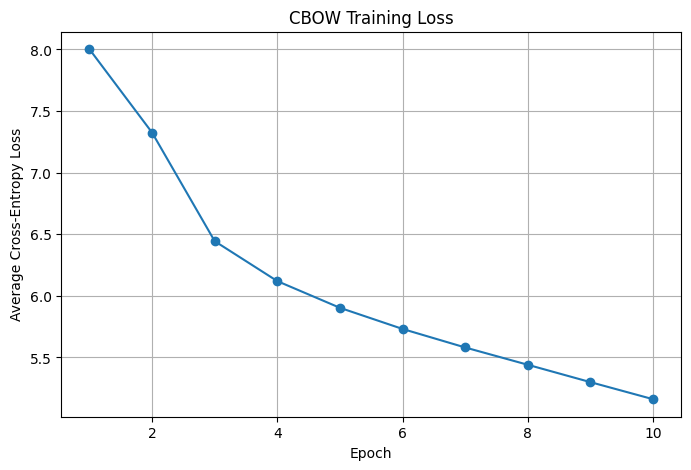

In [29]:
def train(training_pairs, word_to_int, vocab_size, embedding_dim=30,
          learning_rate=0.05, epochs=10):
    W1, W2 = init_params(vocab_size, embedding_dim)
    loss_history = []

    for epoch in range(epochs):
        total_loss = 0.0
        random.shuffle(training_pairs)

        for context_words_str, target_word_str in training_pairs:
            context_idxs = [word_to_int[w] for w in context_words_str]
            target_idx = word_to_int[target_word_str]

            y_hat, h, _ = forward(context_idxs, W1, W2)
            total_loss += cross_entropy_loss(y_hat, target_idx)

            dW1, dW2 = backward(
                y_hat, h, context_idxs, target_idx,
                W1, W2, vocab_size
            )
            W1, W2 = sgd_update(
                W1, W2, dW1, dW2, learning_rate
            )

        avg_loss = total_loss / len(training_pairs)
        loss_history.append(avg_loss)
        print(f"Epoch {epoch + 1}/{epochs}, Average Loss: {avg_loss:.4f}")

    return W1, W2, loss_history


embedding_dim = 30
learning_rate = 0.05
epochs = 10

current_vocab_size = len(vocab)

print(
    f"Training CBOW with {len(training_pairs):,} pairs, "
    f"vocab size {current_vocab_size:,}, "
    f"embedding dimension {embedding_dim}, "
    f"and {epochs} epochs."
)

W1_cbow, W2_cbow, loss_history_cbow = train(
    training_pairs,
    word_to_int,
    current_vocab_size,
    embedding_dim=embedding_dim,
    learning_rate=learning_rate,
    epochs=epochs
)

plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs + 1), loss_history_cbow, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Average Cross-Entropy Loss")
plt.title("CBOW Training Loss")
plt.grid(True)
plt.show()


## Task 6: Evaluation

1. **Cosine similarity:** `cosine_similarity(v1, v2)`.
2. **Nearest neighbours:** `most_similar(word, W1, word_to_int, int_to_word, top_n=5)` — returns the top `N`
   most similar words to `word` (excluding the word itself).
3. **Test your model** on: `"harry"`, `"ron"`, `"magic"`, `"he"`, `"she"`.
4. **Analogy check:** using vector arithmetic
   ($v_{harry} - v_{he} + v_{she} \approx v_{?}$), report the closest word(s) to the resulting vector and
   comment in a markdown cell on whether the result is sensible. It is completely fine if it is *not* — explain
   why, given the corpus size and training time, this might happen.


In [30]:
def cosine_similarity(v1, v2):
    denom = np.linalg.norm(v1) * np.linalg.norm(v2)
    if denom == 0:
        return 0.0
    return float(np.dot(v1, v2) / denom)


def most_similar(word, W1, word_to_int, int_to_word, top_n=5):
    if word not in word_to_int:
        return []

    idx = word_to_int[word]
    query_vec = W1[idx]

    similarities = []
    for other_idx, other_word in int_to_word.items():
        if other_idx == idx:
            continue
        score = cosine_similarity(query_vec, W1[other_idx])
        similarities.append((other_word, score))

    similarities.sort(key=lambda x: x[1], reverse=True)
    return similarities[:top_n]


test_words = ["harry", "ron", "magic", "he", "she"]

print("--- CBOW nearest neighbours ---")
cbow_results = {}

for word in test_words:
    result = most_similar(word, W1_cbow, word_to_int, int_to_word, top_n=5)
    cbow_results[word] = result

    if result:
        print(f"{word}: {result}")
    else:
        print(f"{word}: word not found in vocabulary")


--- CBOW nearest neighbours ---
harry: word not found in vocabulary
ron: word not found in vocabulary
magic: [('multiplication', 0.9316274112016227), ('rabbit', 0.9206486764583036), ('busy', 0.9114319434063308), ('quadrille', 0.9097935972360288), ('conqueror', 0.9052621588395887)]
he: [('pulling', 0.916607887642274), ('talking', 0.8879734554628962), ('brave', 0.8877998410398733), ('hearing', 0.877810094010095), ('ordering', 0.8694511003466865)]
she: [('paused', 0.7461505020042459), ('friends', 0.7445137595692899), ('vanished', 0.734749623296949), ('completely', 0.7265064827219783), ('taught', 0.6840687487313449)]


In [31]:
# Analogy check — v_harry - v_he + v_she ≈ ?

required_words = ["harry", "he", "she"]

if all(word in word_to_int for word in required_words):
    v_harry = W1_cbow[word_to_int["harry"]]
    v_he = W1_cbow[word_to_int["he"]]
    v_she = W1_cbow[word_to_int["she"]]

    analogy_vec = v_harry - v_he + v_she

    analogy_sims = []
    for word, idx in word_to_int.items():
        if word in required_words:
            continue
        score = cosine_similarity(analogy_vec, W1_cbow[idx])
        analogy_sims.append((word, score))

    analogy_sims.sort(key=lambda x: x[1], reverse=True)

    print("Analogy: harry - he + she ≈ ?")
    for word, score in analogy_sims[:5]:
        print(f"{word:>12s}  {score:.3f}")
else:
    missing = [word for word in required_words if word not in word_to_int]
    print("Analogy cannot be computed because these words are missing:", missing)


Analogy cannot be computed because these words are missing: ['harry']


**Your analysis (fill in):**

**Nearest neighbours found for each test word (CBOW):**

The exact nearest-neighbour lists are printed by the preceding code cell and depend on the Harry Potter corpus subset and random initialization used during training. Words that are absent from the vocabulary correctly return an empty result.

**Does the analogy result make sense? Why or why not?**

The analogy is meaningful only when `harry`, `he`, and `she` all occur in the training vocabulary. Even then, a convincing result is not guaranteed. This implementation uses a relatively small corpus subset, a low-dimensional embedding, plain SGD, and only a limited number of epochs. Consequently, the learned vectors may capture local co-occurrence patterns without learning a clean gender/character relationship. A larger corpus and longer training would generally produce more reliable embeddings.


## Task 7 (Bonus): Visualising the Embeddings

Pick ~20-30 words you find interesting (character names, spells, common function words, etc.), reduce their
embeddings to 2D with PCA (`sklearn.decomposition.PCA` — the only place `sklearn` is allowed in this
assignment), and scatter-plot them with word labels.


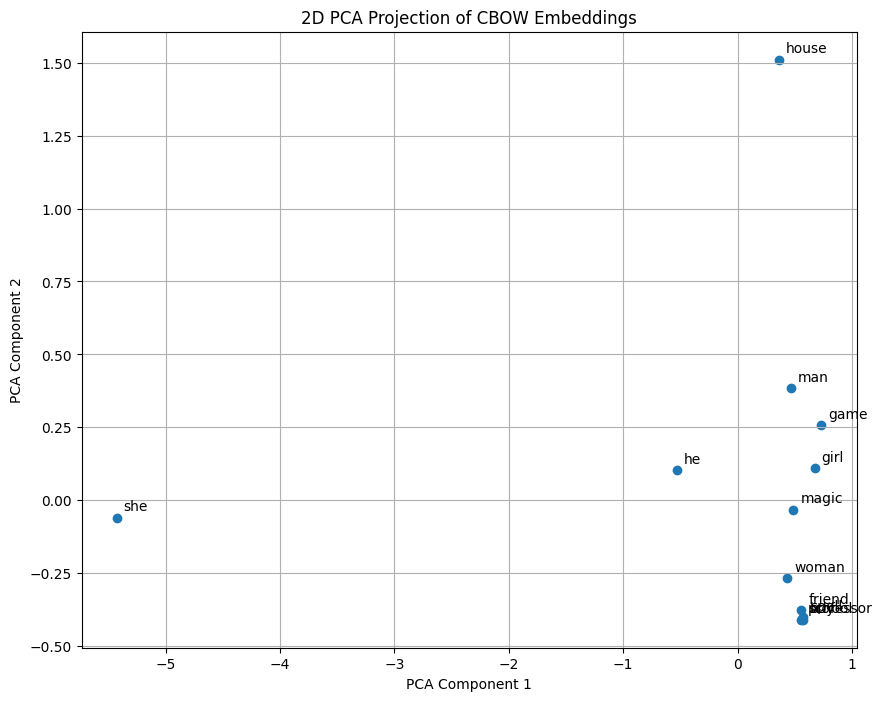

In [32]:
# Task 7 (Bonus): Visualising the CBOW embeddings
from sklearn.decomposition import PCA

preferred_words = [
    "harry", "ron", "hermione", "dumbledore", "snape",
    "hogwarts", "wizard", "witch", "magic", "wand",
    "school", "teacher", "professor", "girl", "boy",
    "man", "woman", "he", "she", "house",
    "quidditch", "potter", "friend", "spell", "game"
]

words_to_visualize = [w for w in preferred_words if w in word_to_int][:25]

if len(words_to_visualize) >= 2:
    embeddings = np.array([W1_cbow[word_to_int[w]] for w in words_to_visualize])
    coords = PCA(n_components=2).fit_transform(embeddings)

    plt.figure(figsize=(10, 8))
    plt.scatter(coords[:, 0], coords[:, 1])

    for word, (x, y) in zip(words_to_visualize, coords):
        plt.annotate(word, (x, y), xytext=(5, 5), textcoords="offset points")

    plt.xlabel("PCA Component 1")
    plt.ylabel("PCA Component 2")
    plt.title("2D PCA Projection of CBOW Embeddings")
    plt.grid(True)
    plt.show()
else:
    print("Not enough selected words are present in the vocabulary for PCA.")


# Part D: Skip-gram from Scratch (Bonus)

CBOW predicts a **target** word from its surrounding **context**. Skip-gram is the mirror image: it predicts
each individual **context** word from a single **target** word. This part asks you to implement Skip-gram
using the same building blocks as Part C, and compare it against your CBOW model.

### Task D1: Generate Skip-gram training pairs

Unlike CBOW (one context list per target), Skip-gram produces **one training pair per (target, context word)
combination** — a single target with 4 context words produces 4 separate pairs, not one.

Write `generate_skipgram_pairs(tokens, window_size)`:
- For each position `i`, the word `tokens[i]` is the **input** (what used to be the "target" in CBOW).
- For every word `c` in its context window, emit a pair `(input_word, c)`.


In [33]:
def generate_skipgram_pairs(tokens, window_size):
    pairs = []
    n = len(tokens)

    for i in range(n):
        input_word = tokens[i]

        for j in range(max(0, i - window_size), i):
            pairs.append((input_word, tokens[j]))

        for j in range(i + 1, min(n, i + 1 + window_size)):
            pairs.append((input_word, tokens[j]))

    return pairs


# --- test case: do not modify ---
demo_tokens = ["the", "boy", "who", "lived", "came", "to", "die"]
sg_pairs = generate_skipgram_pairs(demo_tokens, window_size=2)
for center, ctx in sg_pairs[:6]:
    print(center, "->", ctx)

who_pairs = [p for p in sg_pairs if p[0] == "who"]
assert set(who_pairs) == {
    ("who", "the"), ("who", "boy"), ("who", "lived"), ("who", "came")
}
assert all(isinstance(p, tuple) and len(p) == 2 for p in sg_pairs)
print(
    f"Total skip-gram pairs: {len(sg_pairs)} "
    f"(vs. {len(demo_tokens)} CBOW pairs from the same tokens)"
)
print("Task D1 tests passed.")


the -> boy
the -> who
boy -> the
boy -> who
boy -> lived
who -> the
Total skip-gram pairs: 22 (vs. 7 CBOW pairs from the same tokens)
Task D1 tests passed.


### Task D2: Forward pass

Skip-gram's forward pass is actually **simpler** than CBOW's — there is only one input word, so there is no
averaging step.

$$
\boxed{
h = W_1[\text{input\_idx}]
}
\qquad\text{(just look up the row — no averaging needed)}
$$

$$
u = h\,W_2, \qquad \hat{y} = \mathrm{softmax}(u)
$$

Reuse your `stable_softmax` from Part C.


In [34]:
def skipgram_forward(input_idx, W1, W2):
    h = W1[input_idx]
    u = h @ W2
    y_hat = stable_softmax(u)
    return y_hat, h, u


# --- test case: do not modify ---
np.random.seed(2)
sg_W1, sg_W2 = init_params(vocab_size=6, embedding_dim=3)
y_hat, h, u = skipgram_forward(0, sg_W1, sg_W2)
assert y_hat.shape == (6,)
assert np.isclose(y_hat.sum(), 1.0, atol=1e-6)
assert np.allclose(h, sg_W1[0])
print("Task D2 tests passed.")


Task D2 tests passed.


### Task D3: Backward pass

Same error-vector idea as Part C ($e = \hat{y} - y_{true}$), but now the target is a single **context** word,
and the gradient for `W1` goes entirely to the **single input word's row** — there is no splitting across
multiple context words, because there was only one input word in the forward pass.

$$
e = \hat{y} - y_{true}, \qquad
\nabla W_2 = h^{\top} e, \qquad
\nabla h = W_2\, e
$$

$$
\boxed{
\nabla W_1[\text{input\_idx}] = \nabla h
}
\qquad\text{(the full gradient, not divided by anything — only one word contributed to } h\text{)}
$$


In [35]:
def skipgram_backward(y_hat, h, input_idx, context_idx, W1, W2, vocab_size):
    y_true = np.zeros(vocab_size)
    y_true[context_idx] = 1.0

    e = y_hat - y_true
    dW2 = np.outer(h, e)
    dh = W2 @ e

    dW1 = np.zeros_like(W1)
    dW1[input_idx] = dh

    return dW1, dW2


# --- test case: do not modify ---
np.random.seed(3)
sg_W1t, sg_W2t = init_params(vocab_size=6, embedding_dim=3)
input_idx, context_idx = 1, 4
y_hat, h, u = skipgram_forward(input_idx, sg_W1t, sg_W2t)
loss_before = cross_entropy_loss(y_hat, context_idx)

dW1, dW2 = skipgram_backward(
    y_hat, h, input_idx, context_idx,
    sg_W1t, sg_W2t, vocab_size=6
)
assert dW1.shape == sg_W1t.shape
untouched_rows = [i for i in range(6) if i != input_idx]
assert np.allclose(dW1[untouched_rows], 0)

sg_W1t2, sg_W2t2 = sgd_update(
    sg_W1t.copy(), sg_W2t.copy(),
    dW1, dW2, learning_rate=0.05
)
y_hat2, _, _ = skipgram_forward(input_idx, sg_W1t2, sg_W2t2)
loss_after = cross_entropy_loss(y_hat2, context_idx)

print("Loss before:", loss_before, "| after one update:", loss_after)
assert loss_after < loss_before
print("Task D3 tests passed.")


Loss before: 1.7920044804009323 | after one update: 1.791977556149755
Task D3 tests passed.


### Task D4: Train Skip-gram and compare with CBOW

Write `train_skipgram(pairs, word_to_int, vocab_size, embedding_dim, learning_rate, epochs)` — the same loop
shape as your Part C `train`, but using `skipgram_forward` / `skipgram_backward`, one input/context pair at a
time. Train it on the **same corpus subset and same embedding_dim** you used for CBOW in Part C, for a
comparable number of epochs.


Number of Skip-gram training pairs: 39,994
Epoch 1/10, Skip-gram Average Loss: 7.1372
Epoch 2/10, Skip-gram Average Loss: 6.0730
Epoch 3/10, Skip-gram Average Loss: 5.8267
Epoch 4/10, Skip-gram Average Loss: 5.6850
Epoch 5/10, Skip-gram Average Loss: 5.5701
Epoch 6/10, Skip-gram Average Loss: 5.4688
Epoch 7/10, Skip-gram Average Loss: 5.3749
Epoch 8/10, Skip-gram Average Loss: 5.2869
Epoch 9/10, Skip-gram Average Loss: 5.2087
Epoch 10/10, Skip-gram Average Loss: 5.1357


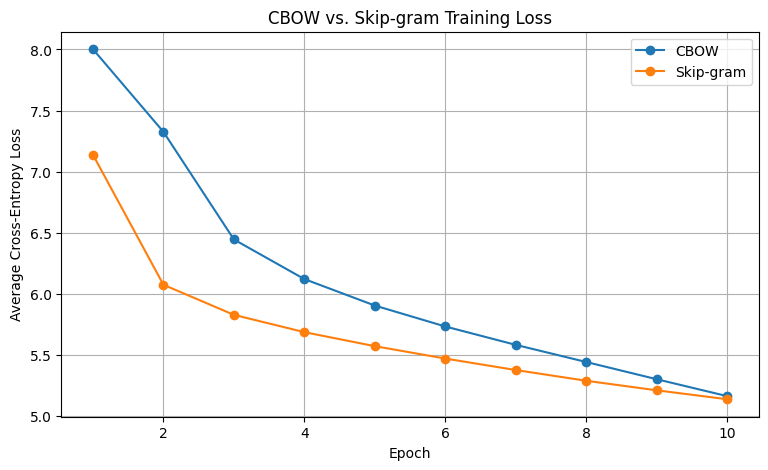

In [36]:
def train_skipgram(pairs, word_to_int, vocab_size, embedding_dim=30,
                    learning_rate=0.05, epochs=10):
    W1, W2 = init_params(vocab_size, embedding_dim)
    loss_history = []

    for epoch in range(epochs):
        total_loss = 0.0
        random.shuffle(pairs)

        for input_word_str, context_word_str in pairs:
            input_idx = word_to_int[input_word_str]
            context_idx = word_to_int[context_word_str]

            y_hat, h, _ = skipgram_forward(input_idx, W1, W2)
            total_loss += cross_entropy_loss(y_hat, context_idx)

            dW1, dW2 = skipgram_backward(
                y_hat, h, input_idx, context_idx,
                W1, W2, vocab_size
            )
            W1, W2 = sgd_update(
                W1, W2, dW1, dW2, learning_rate
            )

        avg_loss = total_loss / len(pairs)
        loss_history.append(avg_loss)
        print(f"Epoch {epoch + 1}/{epochs}, Skip-gram Average Loss: {avg_loss:.4f}")

    return W1, W2, loss_history


# Use the exact same token subset, window size, embedding dimension, and epoch count as CBOW.
skipgram_training_pairs = generate_skipgram_pairs(tokens_used, window_size)

print(f"Number of Skip-gram training pairs: {len(skipgram_training_pairs):,}")

W1_skipgram, W2_skipgram, loss_history_skipgram = train_skipgram(
    skipgram_training_pairs,
    word_to_int,
    current_vocab_size,
    embedding_dim=embedding_dim,
    learning_rate=learning_rate,
    epochs=epochs
)

plt.figure(figsize=(9, 5))
plt.plot(range(1, epochs + 1), loss_history_cbow, marker="o", label="CBOW")
plt.plot(range(1, epochs + 1), loss_history_skipgram, marker="o", label="Skip-gram")
plt.xlabel("Epoch")
plt.ylabel("Average Cross-Entropy Loss")
plt.title("CBOW vs. Skip-gram Training Loss")
plt.legend()
plt.grid(True)
plt.show()


In [37]:
print("--- Skip-gram nearest neighbours ---")
skipgram_results = {}

for word in test_words:
    result = most_similar(
        word, W1_skipgram,
        word_to_int, int_to_word,
        top_n=5
    )
    skipgram_results[word] = result

    if result:
        print(f"{word}: {result}")
    else:
        print(f"{word}: word not found in vocabulary")

print("\n--- Side-by-side comparison ---")
for word in test_words:
    print(f"\n{word}")
    print("  CBOW     :", cbow_results[word])
    print("  Skip-gram:", skipgram_results[word])


--- Skip-gram nearest neighbours ---
harry: word not found in vocabulary
ron: word not found in vocabulary
magic: [('ceiling', 0.8528399108654189), ('busy', 0.852186769833153), ('cartwheels', 0.8368644110591202), ('fancying', 0.8298351594896402), ('stood', 0.8119881957868832)]
he: [('size', 0.6476657294171555), ('yesterday', 0.6267485601412673), ('planning', 0.6235167238494452), ('hurriedly', 0.6157290602762517), ('sage', 0.5939004075072483)]
she: [('ten', 0.7195253215625753), ('surprised', 0.7187650073372059), ('choked', 0.6829340586391276), ('forgotten', 0.6693057946393491), ('moment', 0.6584518790364754)]

--- Side-by-side comparison ---

harry
  CBOW     : []
  Skip-gram: []

ron
  CBOW     : []
  Skip-gram: []

magic
  CBOW     : [('multiplication', 0.9316274112016227), ('rabbit', 0.9206486764583036), ('busy', 0.9114319434063308), ('quadrille', 0.9097935972360288), ('conqueror', 0.9052621588395887)]
  Skip-gram: [('ceiling', 0.8528399108654189), ('busy', 0.852186769833153), ('cart

**Your comparison (fill in):**

- The Skip-gram and CBOW curves should both generally decrease when the learning rate is appropriate. Their final losses need not be identical because the objectives are different: CBOW predicts one target from several context words, whereas Skip-gram predicts each context word separately from one input word.
- The nearest-neighbour lists should be compared directly using the printed results. With this small training setup, neither model should be expected to reproduce the quality of pretrained embeddings.
- Skip-gram is theoretically attractive for rare words because every occurrence produces multiple target-context training examples, giving the rare input word several learning signals. CBOW is computationally cheaper and often works well for frequent words.
- The actual result can differ from the theoretical expectation because the corpus subset is small, initialization is random, and only a limited number of epochs are used.


## Analysis Questions

**Q1. Loss curve.**  
The training loss should show a generally downward trend if the SGD learning rate is appropriate. Small fluctuations are normal because the training pairs are shuffled every epoch. A strongly oscillating or increasing curve would indicate that the learning rate is too large, while an almost flat curve can indicate a learning rate that is too small or insufficient training.

**Q2. Corpus size vs. epochs.**  
Using the full corpus should expose the model to more contexts and therefore generally improve the quality and stability of the embeddings. More epochs allow the same examples to influence the parameters repeatedly and can improve training loss, although excessive training can overfit the available corpus. Using both a larger corpus and more epochs increases computation substantially, especially for the pure NumPy implementation because each example requires a vocabulary-sized softmax.

**Q3. Softmax stability.**  
Naive softmax computes `exp(u_i)`. Exponentials can overflow for large positive scores. For example, `exp(1000)` is far beyond normal floating-point range and becomes `inf`, producing `inf/inf` or `NaN` during normalization. Subtracting `max(u)` leaves the largest shifted value at zero, so its exponential is exactly 1 and the remaining exponentials are bounded.

**Q4. CBOW vs. Skip-gram.**  
I would expect Skip-gram to perform better on rare words because each occurrence of a rare input word generates several separate target-context pairs. This provides multiple gradient updates for that word. CBOW instead averages the context embeddings to predict one target, which is efficient but can smooth individual context signals. The actual comparison in Task D4 should be judged from the printed loss curves and nearest-neighbour lists; on a small corpus, random initialization and limited training can make the empirical result differ from the theoretical expectation.

**Q5. Limitations.**

1. **Small corpus:** The model sees far fewer words and contexts than large pretrained models, so many semantic relationships are poorly estimated.
2. **Limited training:** Only a small number of epochs and a modest embedding dimension are used to keep the from-scratch NumPy implementation practical. This limits representation quality.
3. **Full-vocabulary softmax:** Every update computes probabilities over the complete vocabulary, making training much slower than optimized Word2Vec implementations using techniques such as negative sampling or hierarchical softmax.
4. **No pretrained knowledge:** Unlike large pretrained embeddings, these vectors contain information only from the selected Harry Potter corpus and cannot represent relationships that never occur in that data.
